## The Data

At this link, you will find a dataset containing information about heart disease patients: https://www.dropbox.com/scl/fi/0vrpdnq5asmeulc4gd50y/ha_1.csv?rlkey=ciisalceotl77ffqhqe3kujzv&dl=1

A description of the original dataset can be found here: https://archive.ics.uci.edu/dataset/45/heart+disease (However, this dataset has been cleaned and reduced, and the people have been given fictious names.)

In [1]:
import numpy as np
import pandas as pd

In [6]:
ha = pd.read_csv("ha_1.csv")
ha.head()

,Name,age,sex,cp,trtbps,chol,restecg,thalach,diagnosis
0,Magnolia Cassin,60,1,1,117,230,1,160,No Disease
1,Dr. Cathern Heathcote,60,0,3,102,318,1,160,Disease
2,Miles Wolf,62,0,3,130,263,1,97,No Disease
3,Mikaila Block,43,1,1,115,303,1,181,Disease
4,Mrs. Jacquline Marquardt,66,1,1,120,302,0,151,Disease


## 1. Logistic Regression

Fit a Logistic Regression using only `age` and `chol` (cholesterol) as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

How high for the doctors to estimate a 90% chance that heart disease is present?

In [8]:
from sklearn.linear_model import LogisticRegression

# Select predictors and make Disease equal to 1
X = ha[["age", "chol"]]
y = (ha["diagnosis"] == "Disease").astype(int)

# Fit the model
logistic_model = LogisticRegression()
logistic_model.fit(X, y)

# Get the model coefficients
b0 = logistic_model.intercept_[0]
b_age, b_chol = logistic_model.coef_[0]

# Cholesterol at the 50% decision boundary for age 55
chol_50 = -(b0 + b_age * 55) / b_chol

# Cholesterol corresponding to a 90% disease probability
chol_90 = (
    np.log(0.90 / 0.10) - b0 - b_age * 55
) / b_chol

print("50% decision boundary:", chol_50)
print("90% probability:", chol_90)

50% decision boundary: 367.8748897986282
90% probability: -851.9660996779842


## 2. Linear Discriminant Analysis

Fit an LDA model using only `age` and `chol` (cholesterol)  as predictors.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [9]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X, y)

b0 = lda_model.intercept_[0]
b_age, b_chol = lda_model.coef_[0]

chol_boundary = -(b0 + b_age * 55) / b_chol

print("Decision boundary:", chol_boundary)

Decision boundary: 366.83135143826087


## 3. Support Vector Classifier

Fit an SVC model using only `age` and `chol` as predictors.  Don't forget to tune the regularization parameter.

For a 55 year old, how high would their cholesterol need to be for the doctors to predict heart disease is present?

In [10]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    SVC(kernel="linear"),
    param_grid={"C": [0.001, 0.01, 0.1, 1, 10]},
    scoring="f1_macro",
    cv=10
)

grid_search.fit(X, y)

svc_model = grid_search.best_estimator_

b0 = svc_model.intercept_[0]
b_age, b_chol = svc_model.coef_[0]

chol_boundary = -(b0 + b_age * 55) / b_chol

print("Best C:", grid_search.best_params_["C"])
print("Decision boundary:", chol_boundary)

Best C: 0.1
Decision boundary: 312.6638186400894


## 4. Comparing Decision Boundaries

Make a scatterplot of `age` and `chol`, coloring the points by their true disease outcome.  Add a line to the plot representing the **linear separator** (aka **decision boundary**) for each of the three models above.

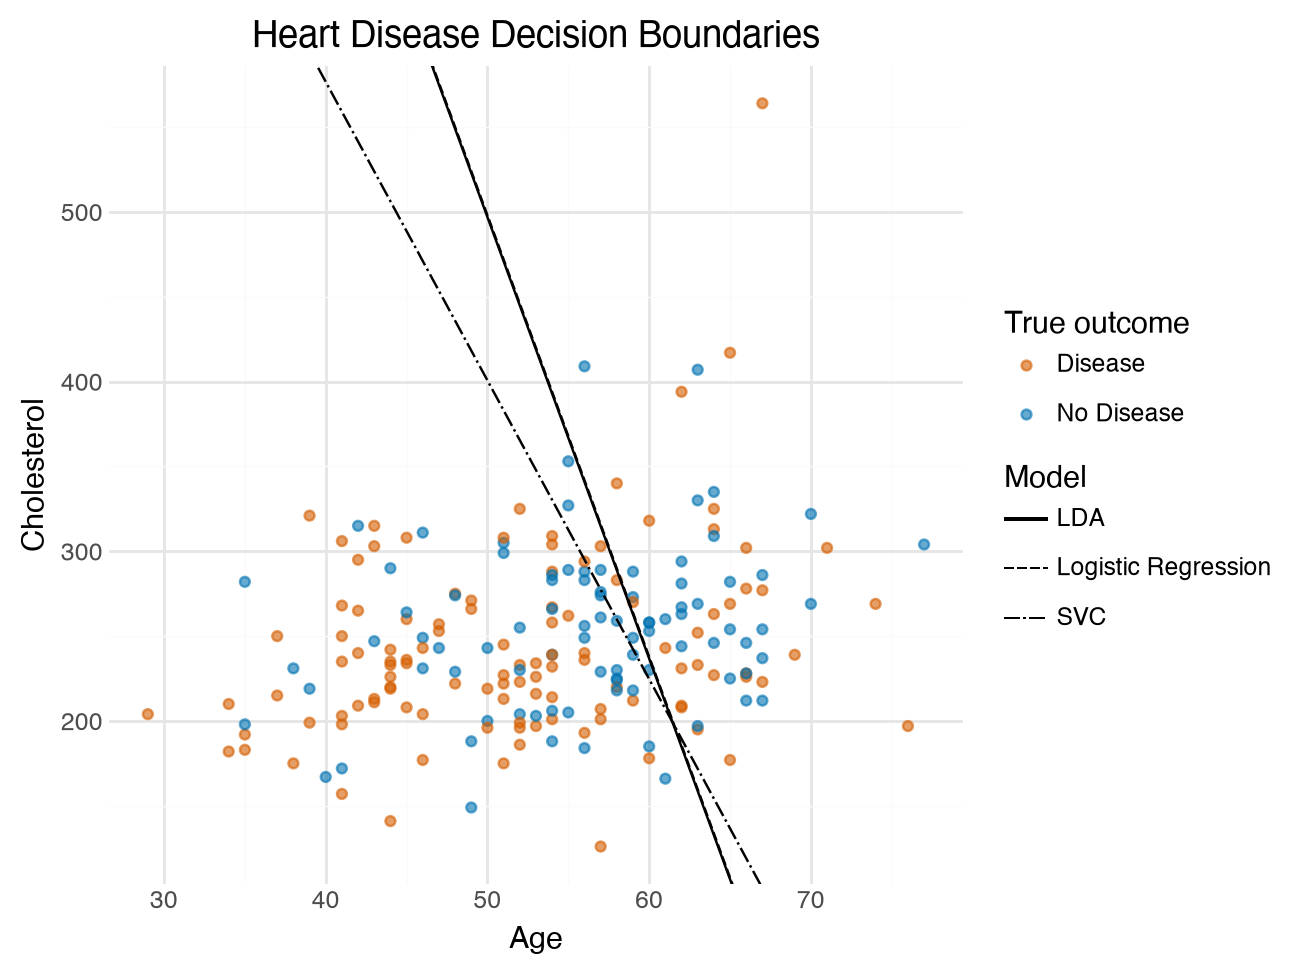

In [11]:
from plotnine import *

models = {
    "Logistic Regression": logistic_model,
    "LDA": lda_model,
    "SVC": svc_model
}

boundaries = pd.DataFrame([
    {
        "model": name,
        "intercept": -model.intercept_[0] / model.coef_[0, 1],
        "slope": -model.coef_[0, 0] / model.coef_[0, 1]
    }
    for name, model in models.items()
])

(
    ggplot(ha, aes(x="age", y="chol", color="diagnosis"))
    + geom_point(alpha=0.6)
    + geom_abline(
        data=boundaries,
        mapping=aes(
            intercept="intercept",
            slope="slope",
            linetype="model"
        ),
        inherit_aes=False,
        color="black"
    )
    + scale_color_manual(
        values={"Disease": "#D55E00", "No Disease": "#0072B2"}
    )
    + labs(
        title="Heart Disease Decision Boundaries",
        x="Age",
        y="Cholesterol",
        color="True outcome",
        linetype="Model"
    )
    + theme_minimal()
)